In [42]:
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats

In [166]:
# X -> Y 
size = 100000
xs = np.random.standard_t(3, size=(size, 1)) 
ny = np.random.normal(0, 1, size=(size, 1))

y = 2 * xs + ny

In [167]:
def get_residuals(xs, y):
    model1 = LinearRegression()
    model1.fit(xs, y)

    residuals = (model1.predict(xs) - y)
    return residuals, model1.coef_.flatten()[0], model1.intercept_[0]

ny, alpha, a = get_residuals(xs, y)
nx, beta, b = get_residuals(y, xs)

print(f"alpha={alpha}")
print(f"beta={beta}")

stat, px = stats.shapiro(xs)
print("Shapiro-Wilk px =", px)

stat, pny = stats.shapiro(ny)
print("Shapiro-Wilk pny =", pny)

if px <= 0.05 or pny <= 0.05:
    print("(X, Y) is not jointly Gaussian, can proceed with test")
else:
    print("(X, Y) is jointly Gaussian")


alpha=2.0007687123731457
beta=0.46069630281652524
Shapiro-Wilk px = 1.1236475793975266e-125
Shapiro-Wilk pny = 0.48995319751460414
(X, Y) is not jointly Gaussian, can proceed with test


/home/martin/PycharmProjects/causality/.venv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 100000.
  res = hypotest_fun_out(*samples, **kwds)


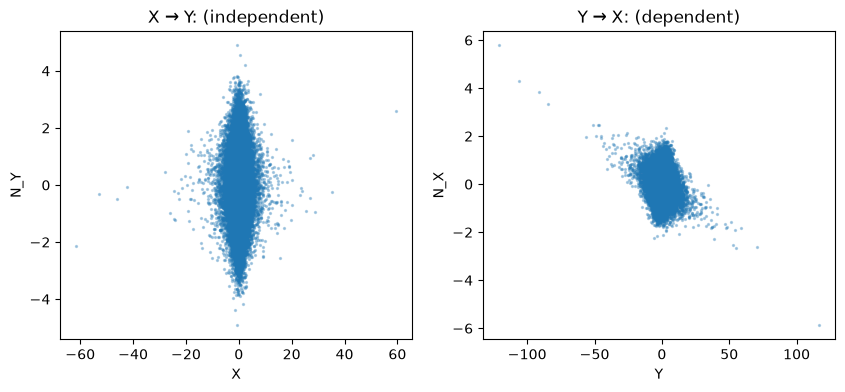

In [169]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].scatter(xs, ny, s=2, alpha=0.3)
axes[0].set_xlabel("X"); axes[0].set_ylabel("N_Y")
axes[0].set_title("X → Y: (independent)")

axes[1].scatter(y, nx, s=2, alpha=0.3)
axes[1].set_xlabel("Y"); axes[1].set_ylabel("N_X")
axes[1].set_title("Y → X: (dependent)")

plt.show()